In [1]:
# 0. SETUP
import os, sys, json, time, math, pickle, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib
if os.environ.get("A3_QUICK", "0") == "1": matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")

ROLL = "M26ECM510"
SEED = int("".join(c for c in ROLL if c.isdigit()))          # 26510
assert SEED == 26510
QUICK = os.environ.get("A3_QUICK", "0") == "1"                # QUICK=1 -> tiny fake-data smoke test
OUT = os.environ.get("A3_OUT", "a3_outputs")
if not QUICK:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT = "/content/drive/MyDrive/ML_Assignment_3/a3_outputs"
    except Exception:
        pass
os.makedirs(OUT + "/ckpt", exist_ok=True); os.makedirs(OUT + "/figs", exist_ok=True)

dev = "cuda" if torch.cuda.is_available() else "cpu"
AMP = dev == "cuda"
if dev == "cuda":
    torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
print("device:", dev, "| QUICK:", QUICK, "| OUT:", OUT)

CFG = dict(val_per_class=500, bs=128, epochs=30, lr_grid=[3e-4, 1e-3, 3e-3], seeds=3,
           q1b_epochs=120, q1b_noisy_seeds=3, q1b_lr=3e-4,
           ae_epochs=40, ae_seeds=2, ae_dims=[32, 128, 512], sigmas=[0.1, 0.2, 0.3, 0.4],
           svm_per_class=800, svm_max_iter=200000, svm_C=[1e-2, 1e-1, 1, 10, 100, 1000],
           k_grid=[6, 8, 10, 12, 15, 20], km_ninit=10, n_boot=2000)
if QUICK:
    CFG.update(val_per_class=50, epochs=2, seeds=2, q1b_epochs=3, q1b_noisy_seeds=2, ae_epochs=2, ae_seeds=2,
               svm_per_class=40, svm_max_iter=3000, svm_C=[1e-2, 1e-1, 1, 10, 100, 1000], k_grid=[4, 6],
               km_ninit=2, n_boot=100, lr_grid=[1e-3, 3e-3])
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
FORCE = os.environ.get("A3_FORCE", "0") == "1"

def cached(name, fn):
    p = f"{OUT}/{name}.pkl"
    if os.path.exists(p) and not FORCE:
        print(f"[cache] loaded {name}"); return pickle.load(open(p, "rb"))
    t = time.time(); r = fn(); pickle.dump(r, open(p, "wb")); print(f"[done] {name} in {time.time()-t:.0f}s"); return r

def savefig(name):
    plt.savefig(f"{OUT}/figs/{name}.pdf", bbox_inches="tight"); plt.savefig(f"{OUT}/figs/{name}.png", dpi=200, bbox_inches="tight"); plt.show()

def set_seed(s):
    torch.manual_seed(s); np.random.seed(s)
    if dev == "cuda": torch.cuda.manual_seed_all(s)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | QUICK: False | OUT: /content/drive/MyDrive/ML_Assignment_3/a3_outputs


In [2]:
# 1. DATA: stratified 45k/5k split (seed = roll digits), train-only normalisation stats
def load_raw():
    if QUICK:
        r = np.random.default_rng(0)
        return (r.integers(0, 256, (5000, 32, 32, 3), dtype=np.uint8), r.integers(0, 10, 5000),
                r.integers(0, 256, (1000, 32, 32, 3), dtype=np.uint8), r.integers(0, 10, 1000))
    from torchvision import datasets
    tr = datasets.CIFAR10("data", train=True, download=True); te = datasets.CIFAR10("data", train=False, download=True)
    return tr.data, np.array(tr.targets), te.data, np.array(te.targets)

Xtr_u8, ytr_np, Xte_u8, yte_np = load_raw()
rng = np.random.default_rng(SEED)
val_idx = np.concatenate([rng.choice(np.where(ytr_np == c)[0], CFG["val_per_class"], replace=False) for c in range(10)])
tr_idx = np.setdiff1d(np.arange(len(ytr_np)), val_idx)
if os.path.exists("split.npz") and not QUICK:           # your PyCharm split must match exactly
    s = np.load("split.npz"); assert (s["train"] == tr_idx).all() and (s["val"] == val_idx).all(), "split.npz mismatch"
    print("split.npz from your repo matches the regenerated split")
np.savez(f"{OUT}/split.npz", train=tr_idx, val=val_idx, seed=SEED)

def to_t(u8): return torch.tensor(u8).permute(0, 3, 1, 2).float().div(255)
_all = to_t(Xtr_u8)
D = dict(Xtr=_all[tr_idx].to(dev), ytr=torch.tensor(ytr_np[tr_idx]).to(dev),
         Xva=_all[val_idx].to(dev), yva=torch.tensor(ytr_np[val_idx]).to(dev))
del _all
MEAN = D["Xtr"].mean((0, 2, 3)).view(1, 3, 1, 1); STD = D["Xtr"].std((0, 2, 3)).view(1, 3, 1, 1)   # train only
print("train/val:", len(D["Xtr"]), len(D["Xva"]), "val class counts:", np.bincount(D["yva"].cpu().numpy()))

_TE = {}
def get_test():
    """TEST SET. Only call from cells marked TEST (after all choices for that part are fixed)."""
    if not _TE:
        _TE.update(X=to_t(Xte_u8).to(dev), y=torch.tensor(yte_np).to(dev)); print("[TEST] test set loaded")
    return _TE

train/val: 45000 5000 val class counts: [500 500 500 500 500 500 500 500 500 500]


In [3]:
# 2. MODELS + TRAINING UTILITIES (models take raw [0,1] images and normalise internally)
class Norm(nn.Module):
    def __init__(s):
        super().__init__(); s.register_buffer("m", MEAN.clone().cpu()); s.register_buffer("s", STD.clone().cpu())
    def forward(s, x): return (x - s.m) / s.s

def mlp(h1, h2):
    return lambda: nn.Sequential(Norm(), nn.Flatten(), nn.Linear(3072, h1), nn.ReLU(), nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, 10))
def cnn(c=64):
    def blk(i, o): return [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2)]
    return lambda: nn.Sequential(Norm(), *blk(3, c), *blk(c, 2 * c), *blk(2 * c, 4 * c), nn.Flatten(), nn.Linear(4 * c * 16, 10))
def big_mlp():
    return nn.Sequential(Norm(), nn.Flatten(), nn.Linear(3072, 2048), nn.ReLU(), nn.Linear(2048, 2048), nn.ReLU(), nn.Linear(2048, 10))
MODELS = {"MLP-S": mlp(128, 64), "MLP-L": mlp(512, 256), "CNN": cnn(64)}
def n_params(m): return sum(p.numel() for p in m.parameters())
def sd_cpu(m): return {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}
def build(make, sd): m = make().to(dev); m.load_state_dict(sd); return m.eval()

def predict_logits(model, X, bs=2000):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs): out.append(model(X[i:i + bs]).float())
    return torch.cat(out)
def eval_cls(model, X, y):
    lg = predict_logits(model, X); return F.cross_entropy(lg, y).item(), (lg.argmax(1) == y).float().mean().item()

def train_epoch(model, opt, scaler, X, y, bs):
    model.train(); perm = torch.randperm(len(X), device=dev); tot = torch.zeros((), device=dev)
    for i in range(0, len(X), bs):
        idx = perm[i:i + bs]
        with torch.autocast(device_type=dev, dtype=torch.float16, enabled=AMP):
            loss = F.cross_entropy(model(X[idx]), y[idx])
        opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tot += loss.detach() * len(idx)
    return tot.item() / len(X)

def fit_cls(make, Xtr, ytr, Xva, yva, lr, epochs, seed):
    """Adam, fixed epochs, checkpoint with best VAL accuracy. Same protocol for every model."""
    set_seed(seed); model = make().to(dev); opt = torch.optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler(dev, enabled=AMP); hist, best = [], (-1, None, 0)
    for ep in range(1, epochs + 1):
        trl = train_epoch(model, opt, scaler, Xtr, ytr, CFG["bs"])
        tl, ta = eval_cls(model, Xtr, ytr); vl, va = eval_cls(model, Xva, yva)
        hist.append(dict(epoch=ep, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va))
        if va > best[0]: best = (va, sd_cpu(model), ep)
    return dict(state=best[1], hist=hist, best_val=best[0], best_epoch=best[2], lr=lr, seed=seed)

def train_model_set(make, Xtr, ytr, Xva, yva, lr_grid, seeds, epochs, fixed_lr=None):
    scores, runs0 = {}, {}
    if fixed_lr is None:
        for lr in lr_grid:
            runs0[lr] = fit_cls(make, Xtr, ytr, Xva, yva, lr, epochs, 0); scores[lr] = runs0[lr]["best_val"]
        best_lr = max(scores, key=scores.get)
    else: best_lr = fixed_lr
    runs = [runs0[best_lr] if (best_lr in runs0 and s == 0) else fit_cls(make, Xtr, ytr, Xva, yva, best_lr, epochs, s) for s in range(seeds)]
    return dict(params=n_params(make()), lr_scores=scores, best_lr=best_lr, runs=runs)

def ms(a, f="{:.2f}"): a = np.array(a) * 100; return (f + " ± " + f).format(a.mean(), a.std(ddof=0))

[cache] loaded q1a
model  params  best_lr                                       lr_val_scores      val_acc  best_epochs
MLP-S  402250   0.0003  {'0.0003': 0.5332, '0.001': 0.52, '0.003': 0.5058} 53.09 ± 0.44 [14, 12, 12]
MLP-L 1707274   0.0003 {'0.0003': 0.5512, '0.001': 0.5328, '0.003': 0.512} 55.03 ± 0.33 [13, 11, 12]
  CNN  412682   0.0010 {'0.0003': 0.803, '0.001': 0.8196, '0.003': 0.7992} 82.18 ± 0.22 [27, 29, 30]


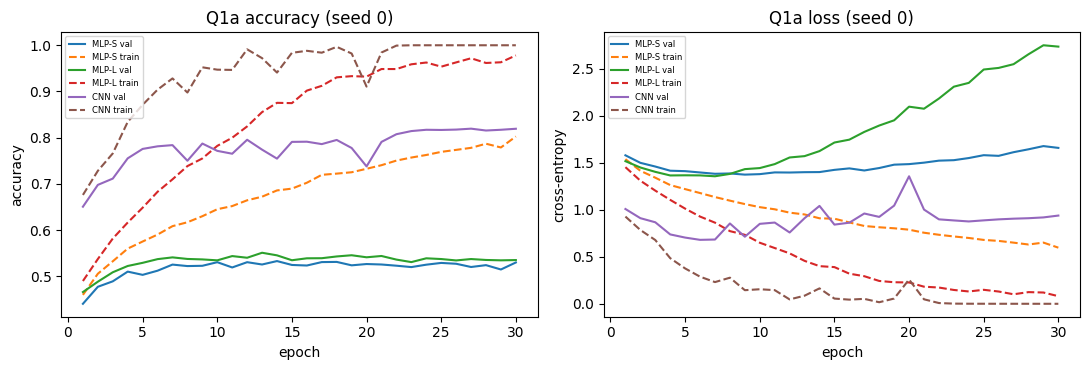

In [4]:
# ===================== Q1(a): why does an MLP do poorly? capacity vs spatial inductive bias =====================
# Reason chosen: MLP has no locality / weight-sharing (spatial inductive bias).  Rival: MLP is simply too small.
# Models: MLP-S (~0.40M) vs CNN (~0.41M, matched within 5%) vs MLP-L (~4x params). Same optimizer, epochs, batch size,
# no augmentation, same LR grid tuned on VAL, checkpoint chosen by VAL.  If MLP-L stays below the CNN, capacity is not the explanation.
def sec_q1a():
    return {n: train_model_set(mk, D["Xtr"], D["ytr"], D["Xva"], D["yva"], CFG["lr_grid"], CFG["seeds"], CFG["epochs"]) for n, mk in MODELS.items()}
Q1A = cached("q1a", sec_q1a)

rows = [dict(model=n, params=r["params"], best_lr=r["best_lr"], lr_val_scores={f"{k:g}": round(v, 4) for k, v in r["lr_scores"].items()},
             val_acc=ms([x["best_val"] for x in r["runs"]]), best_epochs=[x["best_epoch"] for x in r["runs"]]) for n, r in Q1A.items()]
T_q1a = pd.DataFrame(rows); print(T_q1a.to_string(index=False)); T_q1a.to_csv(f"{OUT}/q1a_table.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for n, r in Q1A.items():
    h = r["runs"][0]["hist"]; e = [x["epoch"] for x in h]
    ax[0].plot(e, [x["val_acc"] for x in h], label=f"{n} val"); ax[0].plot(e, [x["train_acc"] for x in h], "--", label=f"{n} train")
    ax[1].plot(e, [x["val_loss"] for x in h], label=f"{n} val"); ax[1].plot(e, [x["train_loss"] for x in h], "--", label=f"{n} train")
ax[0].set(xlabel="epoch", ylabel="accuracy", title="Q1a accuracy (seed 0)"); ax[1].set(xlabel="epoch", ylabel="cross-entropy", title="Q1a loss (seed 0)")
ax[0].legend(fontsize=6); ax[1].legend(fontsize=6); plt.tight_layout(); savefig("q1a_curves")

[cache] loaded q1b
big MLP params: 10510346
         peak_val_epoch  peak_val  final_val  onset_20  onset_15  onset_25  noisy_true_peak_epoch  noisy_true_peak  noisy_true_final  noisy_fit_final  train_assigned_final
p0.0_s0            28.0     0.558      0.546       NaN       NaN       NaN                    NaN              NaN               NaN              NaN                 0.989
p0.4_s0             4.0     0.480      0.373       6.0       4.0       7.0                    4.0            0.474             0.102            0.988                 0.991
p0.4_s1             6.0     0.473      0.376       6.0       5.0       7.0                    4.0            0.453             0.105            0.978                 0.983
p0.4_s2             4.0     0.482      0.366       6.0       5.0       7.0                    4.0            0.456             0.104            0.978                 0.981
p1.0_s0             1.0     0.129      0.106       8.0       6.0       9.0                    1.

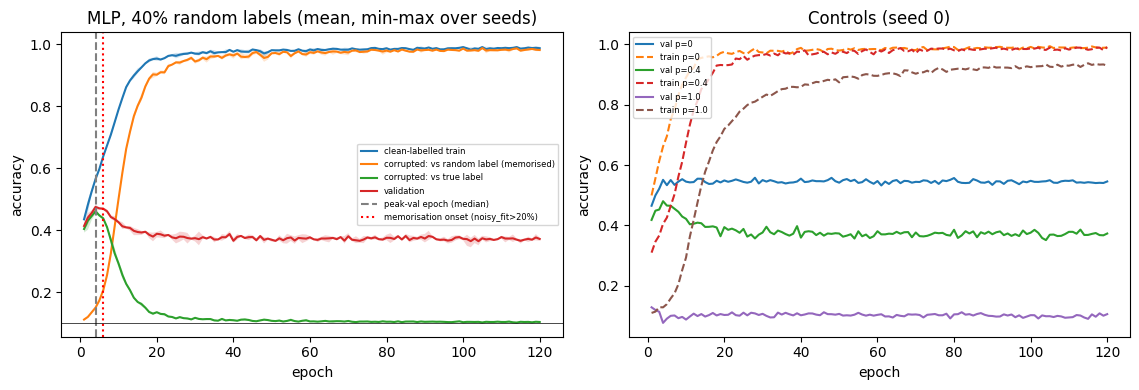

In [5]:
# ===================== Q1(b): memorisation experiment =====================
# Big unregularised MLP (~10.5M params). A fraction p of TRAIN labels is replaced by uniform random labels.
# Logged every epoch: clean_fit (acc on clean-labelled train), noisy_fit (acc on corrupted samples vs their RANDOM label = memorisation),
# noisy_true (acc on corrupted samples vs their TRUE label = structure retained), val_acc (true labels).
# Controls: p=0 (no noise) and p=1.0 (all random: proves capacity).  Chance level of noisy_fit ~ 10%.
def corrupt_labels(y, p):
    r = np.random.default_rng(SEED + 7); u = r.random(len(y)); rl = r.integers(0, 10, len(y))      # nested across p
    noisy = u < p; ya = y.cpu().numpy().copy(); ya[noisy] = rl[noisy]
    return torch.tensor(ya, device=dev), torch.tensor(noisy, device=dev)

def run_q1b(p, seed, epochs):
    ya, noisy = corrupt_labels(D["ytr"], p); clean = ~noisy; yt = D["ytr"]
    set_seed(seed); model = big_mlp().to(dev); opt = torch.optim.Adam(model.parameters(), lr=CFG["q1b_lr"])
    scaler = torch.amp.GradScaler(dev, enabled=AMP); hist, best_val = [], -1
    macc = lambda pr, tg, m: (pr[m] == tg[m]).float().mean().item() if m.any() else float("nan")
    for ep in range(1, epochs + 1):
        trl = train_epoch(model, opt, scaler, D["Xtr"], ya, CFG["bs"])
        pred = predict_logits(model, D["Xtr"]).argmax(1); vl, va = eval_cls(model, D["Xva"], D["yva"])
        hist.append(dict(epoch=ep, train_loss=trl, train_acc_assigned=(pred == ya).float().mean().item(), clean_fit=macc(pred, ya, clean),
                         noisy_fit=macc(pred, ya, noisy), noisy_true=macc(pred, yt, noisy), val_loss=vl, val_acc=va))
        if va > best_val: best_val = va; torch.save(sd_cpu(model), f"{OUT}/ckpt/q1b_p{p}_s{seed}_best.pt")
        if ep % 20 == 0 or ep == 1: h = hist[-1]; print(f"p={p} s={seed} ep{ep}: val={va:.3f} train(assigned)={h['train_acc_assigned']:.3f} noisy_fit={h['noisy_fit']:.3f}")
    torch.save(sd_cpu(model), f"{OUT}/ckpt/q1b_p{p}_s{seed}_final.pt")
    return hist

def sec_q1b():
    cfgs = [(0.0, [0]), (0.4, list(range(CFG["q1b_noisy_seeds"]))), (1.0, [0])]
    return {f"p{p}_s{s}": run_q1b(p, s, CFG["q1b_epochs"]) for p, seeds in cfgs for s in seeds}
Q1B = cached("q1b", sec_q1b); print("big MLP params:", n_params(big_mlp()))

def col(h, k): return np.array([e[k] for e in h], dtype=float)
def summ(h, thr=0.20):
    va = col(h, "val_acc"); nt = col(h, "noisy_true"); nf = col(h, "noisy_fit")
    onset = lambda t: next((e["epoch"] for e in h if e["noisy_fit"] > t), None) if not np.isnan(nf).all() else None
    return dict(peak_val_epoch=int(va.argmax()) + 1, peak_val=va.max(), final_val=va[-1],
                onset_20=onset(0.20), onset_15=onset(0.15), onset_25=onset(0.25),
                noisy_true_peak_epoch=None if np.isnan(nt).all() else int(np.nanargmax(nt)) + 1,
                noisy_true_peak=None if np.isnan(nt).all() else np.nanmax(nt), noisy_true_final=nt[-1], noisy_fit_final=nf[-1], train_assigned_final=h[-1]["train_acc_assigned"])
T_q1b = pd.DataFrame({k: summ(h) for k, h in Q1B.items()}).T; print(T_q1b.round(3).to_string()); T_q1b.to_csv(f"{OUT}/q1b_summary.csv")

keys04 = [k for k in Q1B if k.startswith("p0.4")]; ep = np.arange(1, CFG["q1b_epochs"] + 1)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4))
for key, lab in [("clean_fit", "clean-labelled train"), ("noisy_fit", "corrupted: vs random label (memorised)"), ("noisy_true", "corrupted: vs true label"), ("val_acc", "validation")]:
    A = np.stack([col(Q1B[k], key) for k in keys04]); ax[0].plot(ep, A.mean(0), label=lab); ax[0].fill_between(ep, A.min(0), A.max(0), alpha=0.2)
sm = [summ(Q1B[k]) for k in keys04]
ax[0].axvline(np.median([s["peak_val_epoch"] for s in sm]), ls="--", c="gray", label="peak-val epoch (median)")
ons = [s["onset_20"] for s in sm if s["onset_20"]]
if ons: ax[0].axvline(np.median(ons), ls=":", c="red", label="memorisation onset (noisy_fit>20%)")
ax[0].axhline(0.1, c="k", lw=0.5); ax[0].set(xlabel="epoch", ylabel="accuracy", title="MLP, 40% random labels (mean, min-max over seeds)"); ax[0].legend(fontsize=6)
for k, lab in [("p0.0_s0", "p=0"), ("p0.4_s0", "p=0.4"), ("p1.0_s0", "p=1.0")]:
    ax[1].plot(ep, col(Q1B[k], "val_acc"), label=f"val {lab}"); ax[1].plot(ep, col(Q1B[k], "train_acc_assigned"), "--", label=f"train {lab}")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Controls (seed 0)"); ax[1].legend(fontsize=6); plt.tight_layout(); savefig("q1b_memorisation")

In [6]:
# ===================== Q2: CNN vs MLP, spatial disturbance, third experiment =====================
# (a) FAIRNESS CRITERION (written before looking at results): CNN and MLP-S have parameter counts within 5%; identical optimizer (Adam),
#     epochs, batch size, no augmentation, LR picked on VAL from the same grid, checkpoint picked on VAL. Models/runs reused from Q1a.
# (b) PREDICTION (write/edit this BEFORE running the cell; it is saved with the results):
PRED_B = ("MLP: accuracy essentially unchanged by a fixed pixel permutation (a permutation of inputs is absorbed by its first layer; change within seed noise ~ +-1pt). "
          "CNN: large drop, to roughly MLP level or below, because its locality/weight-sharing prior no longer matches the data.")
# (c) Two explanations for the CNN: A = relies on colour statistics; B = relies on spatial layout of parts (global arrangement).
#     Experiments: grayscale (removes colour, keeps layout) and 4x4 patch shuffle (keeps local texture + colour, destroys layout).
def perm_transform():
    p = torch.tensor(np.random.default_rng(SEED + 1).permutation(1024))
    return lambda X: X.reshape(len(X), 3, 1024)[:, :, p.to(X.device)].reshape(len(X), 3, 32, 32)   # same permutation for all channels
def gray_transform(X): return (0.299 * X[:, 0:1] + 0.587 * X[:, 1:2] + 0.114 * X[:, 2:3]).expand(-1, 3, -1, -1).contiguous()
def patch_transform(grid=4):
    ps = 32 // grid; p = torch.tensor(np.random.default_rng(SEED + 2).permutation(grid * grid))
    def f(X):
        N = len(X); x = X.reshape(N, 3, grid, ps, grid, ps).permute(0, 1, 2, 4, 3, 5).reshape(N, 3, grid * grid, ps, ps)[:, :, p.to(X.device)]
        return x.reshape(N, 3, grid, grid, ps, ps).permute(0, 1, 2, 4, 3, 5).reshape(N, 3, 32, 32)
    return f
TRANSFORMS = {"clean": lambda X: X, "perm": perm_transform(), "gray": gray_transform, "patch": patch_transform(4)}
print("PREDICTION for Q2b:", PRED_B); json.dump(dict(pred_b=PRED_B), open(f"{OUT}/q2b_prediction.json", "w"))

def sec_q2():
    res = {}
    for cond in ["perm", "gray", "patch"]:
        T = TRANSFORMS[cond]; Xt, Xv = T(D["Xtr"]), T(D["Xva"])
        for name in ["MLP-S", "CNN"]:
            res[(name, cond)] = train_model_set(MODELS[name], Xt, D["ytr"], Xv, D["yva"], None, CFG["seeds"], CFG["epochs"], fixed_lr=Q1A[name]["best_lr"])
    return res
Q2 = cached("q2", sec_q2)
Q2.update({(n, "clean"): Q1A[n] for n in ["MLP-S", "CNN"]})
rows = [dict(model=n, condition=c, params=r["params"], lr=r["best_lr"], val_acc=ms([x["best_val"] for x in r["runs"]])) for (n, c), r in sorted(Q2.items())]
print(pd.DataFrame(rows).to_string(index=False))

PREDICTION for Q2b: MLP: accuracy essentially unchanged by a fixed pixel permutation (a permutation of inputs is absorbed by its first layer; change within seed noise ~ +-1pt). CNN: large drop, to roughly MLP level or below, because its locality/weight-sharing prior no longer matches the data.
[cache] loaded q2
model condition  params     lr      val_acc
  CNN     clean  412682 0.0010 82.18 ± 0.22
  CNN      gray  412682 0.0010 79.23 ± 0.16
  CNN     patch  412682 0.0010 73.60 ± 0.25
  CNN      perm  412682 0.0010 54.87 ± 0.36
MLP-S     clean  402250 0.0003 53.09 ± 0.44
MLP-S      gray  402250 0.0003 45.33 ± 0.25
MLP-S     patch  402250 0.0003 52.69 ± 0.29
MLP-S      perm  402250 0.0003 52.73 ± 0.39


[TEST] test set loaded
model condition  params     test_acc conf_correct   conf_wrong          ECE   NLL
  CNN     clean  412682 81.91 ± 0.08 96.66 ± 0.12 81.89 ± 0.28 12.07 ± 0.08 0.909
  CNN      gray  412682 78.81 ± 0.42 95.68 ± 0.15 79.99 ± 0.64 13.55 ± 0.26 1.015
  CNN     patch  412682 72.78 ± 0.10 94.84 ± 0.06 80.99 ± 0.60 18.29 ± 0.14 1.365
  CNN      perm  412682 54.56 ± 0.54 92.13 ± 1.04 81.22 ± 1.69 32.61 ± 1.19 2.718
MLP-S     clean  402250 52.06 ± 0.15 69.03 ± 0.99 50.80 ± 0.70  8.25 ± 0.76 1.398
MLP-S      gray  402250 44.09 ± 0.19 63.47 ± 1.48 48.17 ± 1.53 10.84 ± 1.57 1.651
MLP-S     patch  402250 52.21 ± 0.30 70.25 ± 0.23 52.30 ± 0.31  9.47 ± 0.48 1.415
MLP-S      perm  402250 52.65 ± 0.02 70.03 ± 1.42 52.45 ± 2.07  9.06 ± 1.72 1.412
model  params     lr     test_acc
MLP-S  402250 0.0003 52.06 ± 0.15
MLP-L 1707274 0.0003 54.35 ± 0.32
  CNN  412682 0.0010 81.91 ± 0.08
Clean-trained CNN on transformed test images (no retraining): {'clean': np.float64(81.91), 'perm': np.f

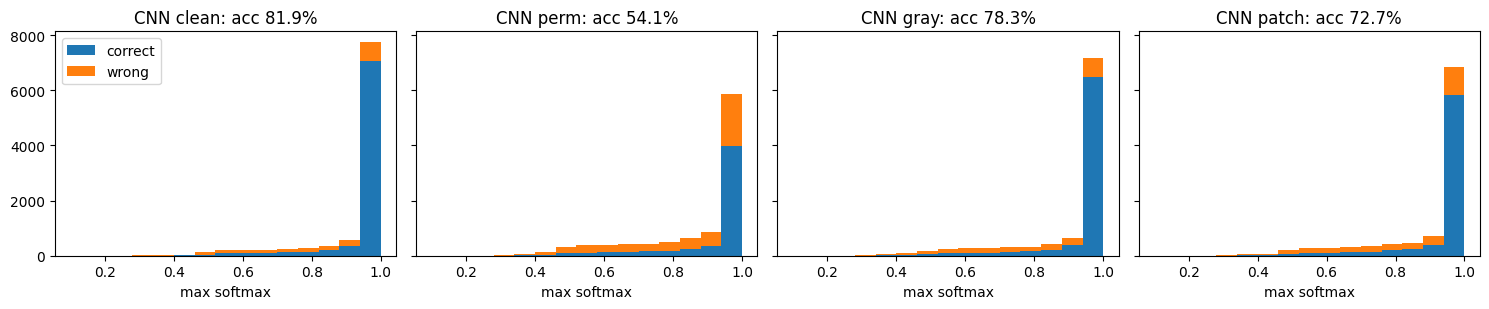

            clean  perm  gray  patch  drop_gray  drop_patch
airplane     84.0  60.7  82.0   77.9        2.1         6.1
automobile   89.6  64.6  89.2   82.6        0.4         7.1
bird         73.1  41.2  66.2   61.1        6.9        12.1
cat          65.5  39.0  60.9   54.0        4.6        11.6
deer         81.0  47.9  76.4   67.7        4.6        13.3
dog          75.2  43.3  71.7   63.6        3.4        11.6
frog         87.5  61.0  84.5   80.6        3.0         6.9
horse        84.6  60.3  82.3   77.7        2.3         6.9
ship         90.1  68.3  87.5   83.3        2.6         6.7
truck        88.5  59.3  87.3   79.3        1.2         9.1
Top-5 confusions (true->pred, count): {
 "clean": [
  [
   "cat",
   "dog",
   136
  ],
  [
   "dog",
   "cat",
   130
  ],
  [
   "automobile",
   "truck",
   68
  ],
  [
   "bird",
   "deer",
   59
  ],
  [
   "cat",
   "bird",
   56
  ]
 ],
 "gray": [
  [
   "dog",
   "cat",
   126
  ],
  [
   "cat",
   "dog",
   121
  ],
  [
   "bird"

In [7]:
# ===================== TEST (Q1 + Q2): all choices above are fixed; evaluate on the official test set =====================
TE = get_test()
def analyse(model, X, y, nb=15):
    lg = predict_logits(model, X); pr = lg.softmax(1); conf, pred = pr.max(1); corr = pred == y; ece = 0.0
    bins = torch.linspace(0, 1, nb + 1, device=dev)
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): ece += m.float().mean().item() * abs(corr[m].float().mean().item() - conf[m].mean().item())
    return dict(acc=corr.float().mean().item(), nll=F.cross_entropy(lg, y).item(), conf_correct=conf[corr].mean().item(),
                conf_wrong=conf[~corr].mean().item() if (~corr).any() else float("nan"), ece=ece,
                perclass=np.array([corr[y == c].float().mean().item() for c in range(10)]), pred=pred.cpu().numpy(), conf=conf.cpu().numpy(), correct=corr.cpu().numpy())

AN = {}   # (model, cond, seed) -> analysis on test set with the SAME transform as in training
for (n, c), r in Q2.items():
    Xt = TRANSFORMS[c](TE["X"])
    for run in r["runs"]: AN[(n, c, run["seed"])] = analyse(build(MODELS[n], run["state"]), Xt, TE["y"])
rows = []
for (n, c), r in sorted(Q2.items()):
    a = [AN[(n, c, s["seed"])] for s in r["runs"]]
    rows.append(dict(model=n, condition=c, params=r["params"], test_acc=ms([x["acc"] for x in a]), conf_correct=ms([x["conf_correct"] for x in a]),
                     conf_wrong=ms([x["conf_wrong"] for x in a]), ECE=ms([x["ece"] for x in a]), NLL=np.mean([x["nll"] for x in a]).round(3)))
T_q2 = pd.DataFrame(rows); print(T_q2.to_string(index=False)); T_q2.to_csv(f"{OUT}/q2_test_table.csv", index=False)

# Q1a deliverable: final test accuracy of the selected comparison models (clean condition) incl. MLP-L
T_q1a_test = pd.DataFrame([dict(model=n, params=Q1A[n]["params"], lr=Q1A[n]["best_lr"],
    test_acc=ms([analyse(build(MODELS[n], s["state"]), TE["X"], TE["y"])["acc"] for s in Q1A[n]["runs"]])) for n in Q1A])
print(T_q1a_test.to_string(index=False)); T_q1a_test.to_csv(f"{OUT}/q1a_test_table.csv", index=False)

# Q2c: CNN clean-trained, evaluated on transformed test images WITHOUT retraining (supplementary diagnostic)
sup = {c: np.mean([analyse(build(MODELS["CNN"], s["state"]), TRANSFORMS[c](TE["X"]), TE["y"])["acc"] for s in Q2[("CNN", "clean")]["runs"]]) for c in TRANSFORMS}
print("Clean-trained CNN on transformed test images (no retraining):", {k: round(v * 100, 2) for k, v in sup.items()})

# error + confidence analysis (CNN conditions, seed 0)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for a, c in zip(ax, ["clean", "perm", "gray", "patch"]):
    r = AN[("CNN", c, 0)]; a.hist([r["conf"][r["correct"]], r["conf"][~r["correct"]]], bins=15, range=(0.1, 1), stacked=True, label=["correct", "wrong"])
    a.set_title(f"CNN {c}: acc {r['acc']*100:.1f}%"); a.set_xlabel("max softmax")
ax[0].legend(); plt.tight_layout(); savefig("q2_confidence")
pc = pd.DataFrame({c: np.mean([AN[("CNN", c, s)]["perclass"] for s in range(CFG["seeds"])], 0) * 100 for c in ["clean", "perm", "gray", "patch"]}, index=CLASSES)
pc["drop_gray"] = pc["clean"] - pc["gray"]; pc["drop_patch"] = pc["clean"] - pc["patch"]; print(pc.round(1).to_string()); pc.to_csv(f"{OUT}/q2_perclass.csv")
cm_pairs = {}
for c in ["clean", "gray", "patch"]:
    cm = np.zeros((10, 10), int); np.add.at(cm, (TE["y"].cpu().numpy(), AN[("CNN", c, 0)]["pred"]), 1); np.fill_diagonal(cm, 0)
    top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:5], cm.shape))[0]; cm_pairs[c] = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i, j in top]
print("Top-5 confusions (true->pred, count):", json.dumps(cm_pairs, indent=1))

# Q1b: test accuracy at the peak-val epoch vs at the end (checkpoints saved during training; no selection uses test)
rows = []
for k in Q1B:
    p, s = k.split("_")[0][1:], k.split("_")[1][1:]
    for tag in ["best", "final"]:
        m = big_mlp().to(dev); m.load_state_dict(torch.load(f"{OUT}/ckpt/q1b_p{p}_s{s}_{tag}.pt")); rows.append(dict(run=k, checkpoint=tag, test_acc=eval_cls(m, TE["X"], TE["y"])[1]))
T_q1b_test = pd.DataFrame(rows); print(T_q1b_test.round(4).to_string(index=False)); T_q1b_test.to_csv(f"{OUT}/q1b_test.csv", index=False)

In [8]:
# ===================== Q3(a): three autoencoders differing only in bottleneck =====================
class AE(nn.Module):
    def __init__(s, d):
        super().__init__()
        s.enc = nn.Sequential(nn.Conv2d(3, 32, 4, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Conv2d(64, 128, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(2048, d))
        s.dec = nn.Sequential(nn.Linear(d, 2048), nn.ReLU(), nn.Unflatten(1, (128, 4, 4)), nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
                              nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Sigmoid())
    def forward(s, x): return s.dec(s.enc(x))

def make_gen(seed): g = torch.Generator(device=dev); g.manual_seed(seed); return g
def add_noise(x, sigma, gen=None): return (x + sigma * torch.randn(x.shape, device=x.device, generator=gen)).clamp(0, 1)
@torch.no_grad()
def recon(ae, X, bs=2000): ae.eval(); return torch.cat([ae(X[i:i + bs]) for i in range(0, len(X), bs)])
def mse(a, b): return F.mse_loss(a, b).item()

def train_ae(d, seed, epochs, sigma=None, lr=1e-3):
    set_seed(seed); ae = AE(d).to(dev); opt = torch.optim.Adam(ae.parameters(), lr=lr); Xtr = D["Xtr"]
    Xva_in = add_noise(D["Xva"], sigma, make_gen(SEED + 3)) if sigma else D["Xva"]
    best = (1e9, None, 0); hist = []
    for ep in range(1, epochs + 1):
        ae.train(); perm = torch.randperm(len(Xtr), device=dev)
        for i in range(0, len(Xtr), CFG["bs"]):
            x = Xtr[perm[i:i + CFG["bs"]]]; inp = add_noise(x, sigma) if sigma else x          # fresh noise every batch
            loss = F.mse_loss(ae(inp), x); opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        v = mse(recon(ae, Xva_in), D["Xva"]); hist.append(dict(epoch=ep, val_mse=v))
        if v < best[0]: best = (v, sd_cpu(ae), ep)
    return dict(state=best[1], val_mse=best[0], best_epoch=best[2], hist=hist, d=d, seed=seed, params=n_params(AE(d)))
def build_ae(d, sd): m = AE(d).to(dev); m.load_state_dict(sd); return m.eval()

def sec_q3a(): return {d: [train_ae(d, s, CFG["ae_epochs"]) for s in range(CFG["ae_seeds"])] for d in CFG["ae_dims"]}
Q3A = cached("q3a", sec_q3a)
T_q3a = pd.DataFrame([dict(bottleneck=d, params=r[0]["params"], val_mse_mean=np.mean([x["val_mse"] for x in r]), val_mse_std=np.std([x["val_mse"] for x in r]),
                           val_mse_seed0=r[0]["val_mse"]) for d, r in Q3A.items()])
print(T_q3a.to_string(index=False)); T_q3a.to_csv(f"{OUT}/q3a_table.csv", index=False)
D_SEL = int(T_q3a.loc[T_q3a.val_mse_mean.idxmin(), "bottleneck"])
srt = T_q3a.sort_values("val_mse_mean"); print(f"Selected (lowest mean val MSE): d={D_SEL}; margin over runner-up = {srt.val_mse_mean.iloc[1]-srt.val_mse_mean.iloc[0]:.5f} vs seed std {srt.val_mse_std.iloc[0]:.5f}")
AE_SEL = build_ae(D_SEL, Q3A[D_SEL][0]["state"])

[cache] loaded q3a
 bottleneck  params  val_mse_mean  val_mse_std  val_mse_seed0
         32  464227      0.011282 7.540453e-06       0.011274
        128  857539      0.004618 3.448222e-07       0.004618
        512 2430787      0.001868 6.101798e-05       0.001807
Selected (lowest mean val MSE): d=512; margin over runner-up = 0.00275 vs seed std 0.00006


In [9]:
# ===================== Q3(b): denoising autoencoder (Gaussian noise) =====================
# Corruption: additive Gaussian noise (clamped to [0,1]). Unlike occlusion it removes no pixel entirely, so reconstruction can plausibly help.
# sigma chosen on VAL: smallest sigma in the grid that drops the fixed CNN's val accuracy by >= 15 points (so there is something to recover).
CLF = build(MODELS["CNN"], Q1A["CNN"]["runs"][0]["state"])          # the fixed CNN classifier (introduced in Q1a, never retrained)
clf_acc = lambda X, y: (predict_logits(CLF, X).argmax(1) == y).float().mean().item()
va_clean = clf_acc(D["Xva"], D["yva"]); sig_tab = {}
for s in CFG["sigmas"]: sig_tab[s] = clf_acc(add_noise(D["Xva"], s, make_gen(SEED + 3)), D["yva"])
print("CNN val acc: clean", round(va_clean, 4), "| by sigma:", {k: round(v, 4) for k, v in sig_tab.items()})
SIGMA = next((s for s in CFG["sigmas"] if va_clean - sig_tab[s] >= 0.15), CFG["sigmas"][-1]); print("chosen sigma:", SIGMA)
Q3B = cached("q3b", lambda: train_ae(D_SEL, 0, CFG["ae_epochs"], sigma=SIGMA))
DAE = build_ae(D_SEL, Q3B["state"])
print("DAE protocol: same architecture as selected AE (d=%d), input = clamp(x + N(0,%.2f^2)) with FRESH noise every batch, target = clean x, "
      "MSE loss, Adam 1e-3, %d epochs, bs %d, checkpoint = best val MSE on fixed-noise val set, no labels used." % (D_SEL, SIGMA, CFG["ae_epochs"], CFG["bs"]))

CNN val acc: clean 0.8196 | by sigma: {0.1: 0.3422, 0.2: 0.1626, 0.3: 0.129, 0.4: 0.1188}
chosen sigma: 0.1
[cache] loaded q3b
DAE protocol: same architecture as selected AE (d=512), input = clamp(x + N(0,0.10^2)) with FRESH noise every batch, target = clean x, MSE loss, Adam 1e-3, 40 epochs, bs 128, checkpoint = best val MSE on fixed-noise val set, no labels used.


Q3a: selected clean AE (d=512) TEST reconstruction MSE = 0.00182
                   classifier_input  test_acc  mse_vs_clean
                  clean test images     81.87        0.0000
              corrupted test images     34.74        0.0093
        clean-AE recon of corrupted     63.60        0.0032
             DAE recon of corrupted     63.33        0.0028
clean-AE recon of clean (blur cost)     68.43        0.0018
     DAE recon of clean (blur cost)     64.17        0.0023
DAE vs corrupted input : {'diff_pts': np.float64(28.59), 'ci95': (np.float64(27.37), np.float64(29.849999999999994)), 'mcnemar_p': np.float64(0.0)}
DAE vs clean-AE recon  : {'diff_pts': np.float64(-0.27000000000000357), 'ci95': (np.float64(-0.9800000000000031), np.float64(0.4799999999999918)), 'mcnemar_p': np.float64(0.4713665134611049)}
Clean->corrupted drop 47.13 pts; DAE recovers 60.7% of it; clean AE recovers 61.2%


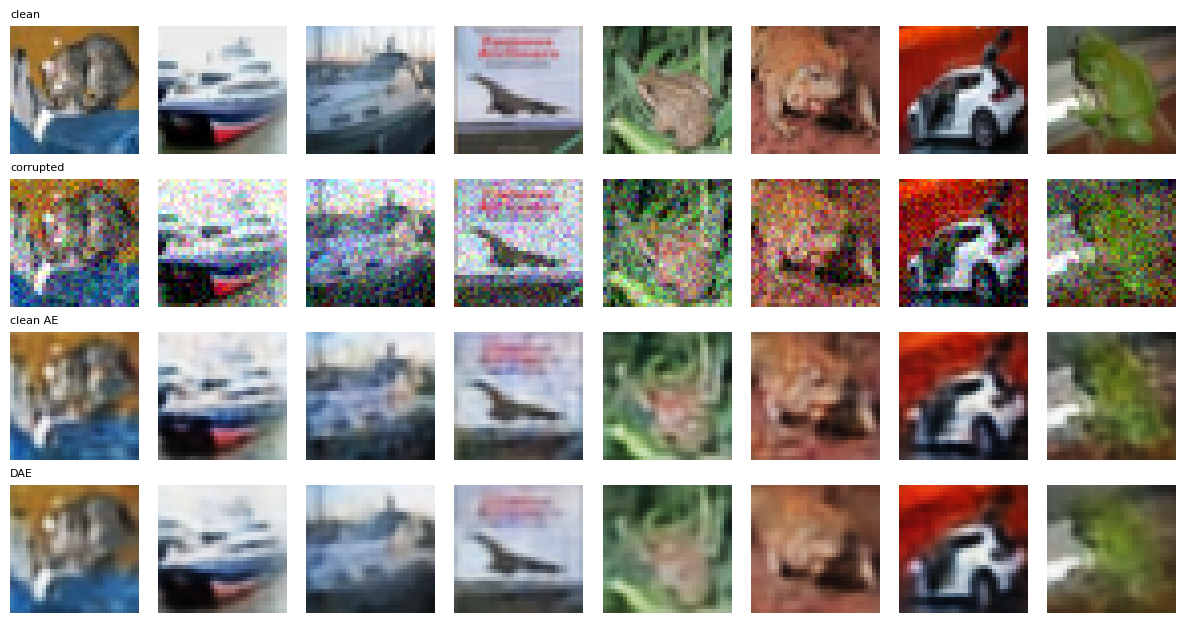

In [10]:
# TEST (Q3a, Q3b)
TE = get_test(); Xte_noisy = add_noise(TE["X"], SIGMA, make_gen(SEED + 4))
print(f"Q3a: selected clean AE (d={D_SEL}) TEST reconstruction MSE = {mse(recon(AE_SEL, TE['X']), TE['X']):.5f}")
inputs = {"clean test images": (TE["X"], TE["X"]), "corrupted test images": (Xte_noisy, TE["X"]),
          "clean-AE recon of corrupted": (recon(AE_SEL, Xte_noisy), TE["X"]), "DAE recon of corrupted": (recon(DAE, Xte_noisy), TE["X"]),
          "clean-AE recon of clean (blur cost)": (recon(AE_SEL, TE["X"]), TE["X"]), "DAE recon of clean (blur cost)": (recon(DAE, TE["X"]), TE["X"])}
corr = {k: (predict_logits(CLF, v[0]).argmax(1) == TE["y"]).cpu().numpy() for k, v in inputs.items()}
T_q3b = pd.DataFrame([dict(classifier_input=k, test_acc=corr[k].mean() * 100, mse_vs_clean=mse(v[0], v[1])) for k, v in inputs.items()]); print(T_q3b.round(4).to_string(index=False)); T_q3b.to_csv(f"{OUT}/q3b_table.csv", index=False)
def paired(a, b, n=CFG["n_boot"]):
    r = np.random.default_rng(0); idx = r.integers(0, len(a), (n, len(a))); d = a[idx].mean(1) - b[idx].mean(1)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum()); pv = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 > 0 else 1.0
    return dict(diff_pts=(a.mean() - b.mean()) * 100, ci95=(np.percentile(d, 2.5) * 100, np.percentile(d, 97.5) * 100), mcnemar_p=pv)
A, B, C0 = corr["DAE recon of corrupted"], corr["corrupted test images"], corr["clean-AE recon of corrupted"]
print("DAE vs corrupted input :", paired(A, B)); print("DAE vs clean-AE recon  :", paired(A, C0))
gap = corr["clean test images"].mean() - B.mean(); print(f"Clean->corrupted drop {gap*100:.2f} pts; DAE recovers {(A.mean()-B.mean())/gap*100:.1f}% of it; clean AE recovers {(C0.mean()-B.mean())/gap*100:.1f}%")
fig, ax = plt.subplots(4, 8, figsize=(12, 6.3)); ids = np.arange(8)
for r_, (lab, X_) in enumerate([("clean", TE["X"]), ("corrupted", Xte_noisy), ("clean AE", inputs["clean-AE recon of corrupted"][0]), ("DAE", inputs["DAE recon of corrupted"][0])]):
    for j, i in enumerate(ids): ax[r_, j].imshow(X_[i].permute(1, 2, 0).cpu().numpy()); ax[r_, j].axis("off")
    ax[r_, 0].set_title(lab, fontsize=8, loc="left")
plt.tight_layout(); savefig("q3b_examples")

                   model  test_recon_mse  probe_val  probe_test    wd
           clean AE d=32          0.0114     0.3780      0.3687 0.000
          clean AE d=128          0.0047     0.4012      0.4044 0.010
          clean AE d=512          0.0018     0.4790      0.4765 0.000
DAE d=512 (clean inputs)          0.0023     0.4814      0.4857 0.001
  raw pixels (reference)          0.0000     0.4002      0.4049 0.010
Spearman(recon MSE, probe test acc) over the clean AEs (only 3 points; weak evidence): SignificanceResult(statistic=np.float64(-1.0), pvalue=np.float64(0.0))


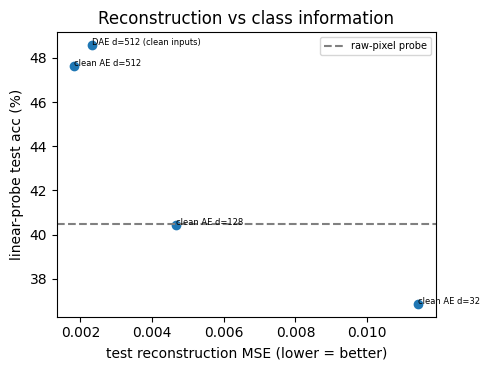

In [11]:
# TEST (Q3c): linear probes on FROZEN encoders vs reconstruction quality
@torch.no_grad()
def encode(ae, X, bs=2000): ae.eval(); return torch.cat([ae.enc(X[i:i + bs]) for i in range(0, len(X), bs)])
def linear_probe(Ftr, ytr, Fva, yva, Fte, yte, wds=(0, 1e-4, 1e-3, 1e-2), steps=300):
    mu, sd = Ftr.mean(0, keepdim=True), Ftr.std(0, keepdim=True) + 1e-6; z = lambda f: (f - mu) / sd; Ftr, Fva, Fte = z(Ftr), z(Fva), z(Fte); best = None
    for wd in wds:
        set_seed(0); lin = nn.Linear(Ftr.shape[1], 10).to(dev); opt = torch.optim.Adam(lin.parameters(), lr=1e-2, weight_decay=wd)
        for _ in range(steps): opt.zero_grad(); F.cross_entropy(lin(Ftr), ytr).backward(); opt.step()
        with torch.no_grad(): va = (lin(Fva).argmax(1) == yva).float().mean().item(); te = (lin(Fte).argmax(1) == yte).float().mean().item()
        if best is None or va > best["val_acc"]: best = dict(val_acc=va, test_acc=te, wd=wd)
    return best                                   # wd chosen on VAL only
rows = []
for d, runs in Q3A.items():
    ae = build_ae(d, runs[0]["state"]); P = linear_probe(encode(ae, D["Xtr"]), D["ytr"], encode(ae, D["Xva"]), D["yva"], encode(ae, TE["X"]), TE["y"])
    rows.append(dict(model=f"clean AE d={d}", test_recon_mse=mse(recon(ae, TE["X"]), TE["X"]), probe_val=P["val_acc"], probe_test=P["test_acc"], wd=P["wd"]))
P = linear_probe(encode(DAE, D["Xtr"]), D["ytr"], encode(DAE, D["Xva"]), D["yva"], encode(DAE, TE["X"]), TE["y"])
rows.append(dict(model=f"DAE d={D_SEL} (clean inputs)", test_recon_mse=mse(recon(DAE, TE["X"]), TE["X"]), probe_val=P["val_acc"], probe_test=P["test_acc"], wd=P["wd"]))
flat = lambda X: X.reshape(len(X), -1); P = linear_probe(flat(D["Xtr"]), D["ytr"], flat(D["Xva"]), D["yva"], flat(TE["X"]), TE["y"])
rows.append(dict(model="raw pixels (reference)", test_recon_mse=0.0, probe_val=P["val_acc"], probe_test=P["test_acc"], wd=P["wd"]))
T_q3c = pd.DataFrame(rows); print(T_q3c.round(4).to_string(index=False)); T_q3c.to_csv(f"{OUT}/q3c_table.csv", index=False)
ae_rows = T_q3c.iloc[:len(Q3A)]
if len(ae_rows) >= 3: print("Spearman(recon MSE, probe test acc) over the clean AEs (only %d points; weak evidence):" % len(ae_rows), stats.spearmanr(ae_rows.test_recon_mse, ae_rows.probe_test))
fig, ax = plt.subplots(figsize=(5, 3.8)); m = T_q3c[T_q3c.model != "raw pixels (reference)"]
ax.scatter(m.test_recon_mse, m.probe_test * 100)
for _, r in m.iterrows(): ax.annotate(r.model, (r.test_recon_mse, r.probe_test * 100), fontsize=6)
ax.axhline(T_q3c.probe_test.iloc[-1] * 100, ls="--", c="gray", label="raw-pixel probe"); ax.set(xlabel="test reconstruction MSE (lower = better)", ylabel="linear-probe test acc (%)", title="Reconstruction vs class information"); ax.legend(fontsize=7)
plt.tight_layout(); savefig("q3c_recon_vs_probe")

representation dim 512; SVM subset 8000 (800/class)
[cache] loaded q4a
kernel       C  train_acc  val_acc  sv_frac  hit_iter_cap  secs
linear    0.01     0.6135   0.4072   0.8945         False  55.5
linear    0.10     0.7110   0.3872   0.8578          True  94.9
linear    1.00     0.8038   0.3754   0.8384          True 127.3
linear   10.00     0.7452   0.3578   0.9539          True 180.3
linear  100.00     0.6695   0.3470   0.9684          True 189.7
linear 1000.00     0.6695   0.3470   0.9684          True 209.9
   rbf    0.01     0.3144   0.2862   1.0000         False 150.5
   rbf    0.10     0.4372   0.3678   0.9940         False 155.1
   rbf    1.00     0.8446   0.4792   0.9705         False 150.1
   rbf   10.00     0.9988   0.4964   0.9750         False 147.5
   rbf  100.00     1.0000   0.4950   0.9750         False 152.5
   rbf 1000.00     1.0000   0.4950   0.9750         False 167.7
  poly    0.01     0.4588   0.3834   0.9949         False  79.6
  poly    0.10     0.7466   0.476

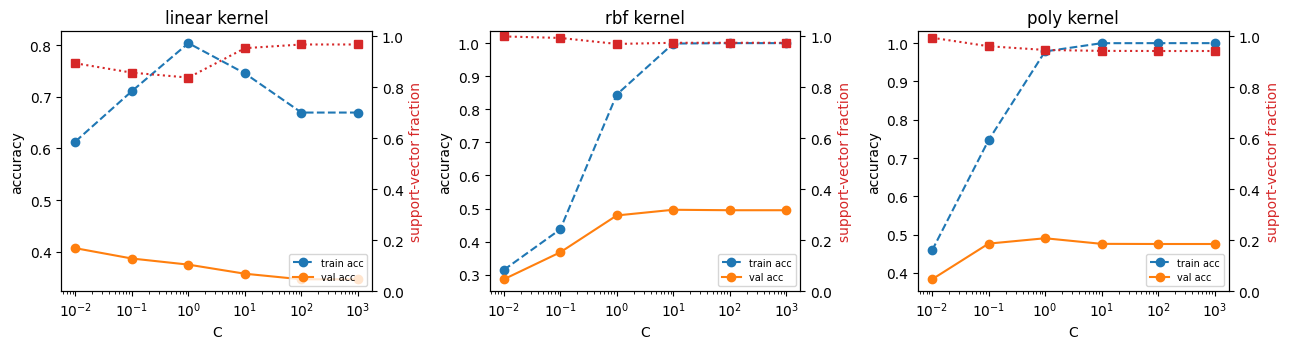

In [12]:
# ===================== Q4 (bonus): SVM on a fixed representation + clustering =====================
# Fixed representation: encoder of the selected clean AE from Q3a (dimension D_SEL), standardised with TRAIN statistics. Never changed in Q4.
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from joblib import Parallel, delayed

Ftr = encode(AE_SEL, D["Xtr"]).cpu().numpy(); Fva = encode(AE_SEL, D["Xva"]).cpu().numpy(); mu, sd = Ftr.mean(0), Ftr.std(0) + 1e-6
Ftr, Fva = (Ftr - mu) / sd, (Fva - mu) / sd; ytr_, yva_ = D["ytr"].cpu().numpy(), D["yva"].cpu().numpy()
r = np.random.default_rng(SEED + 11)       # FIXED stratified subset, drawn BEFORE any model selection and used for every SVM run
sub = np.concatenate([r.choice(np.where(ytr_ == c)[0], CFG["svm_per_class"], replace=False) for c in range(10)]); np.save(f"{OUT}/q4_svm_subset_idx.npy", sub)
Xs, ys = Ftr[sub], ytr_[sub]; print(f"representation dim {Ftr.shape[1]}; SVM subset {len(sub)} ({CFG['svm_per_class']}/class)")

def make_svc(kernel, C):
    kw = dict(kernel=kernel, C=C, gamma="scale", cache_size=1000, max_iter=CFG["svm_max_iter"], decision_function_shape="ovo")
    if kernel == "poly": kw.update(degree=3, coef0=1.0)
    return SVC(**kw)
def one_setting(kernel, C, Xs, ys, Fva, yva):
    t = time.time(); clf = make_svc(kernel, C).fit(Xs, ys)
    try: nit = int(np.max(clf.n_iter_))
    except Exception: nit = -1
    return dict(kernel=kernel, C=C, train_acc=clf.score(Xs, ys), val_acc=clf.score(Fva, yva), sv_frac=clf.n_support_.sum() / len(ys),
                hit_iter_cap=bool(nit >= CFG["svm_max_iter"]), secs=round(time.time() - t, 1))
NJ = 1 if QUICK else min(4, os.cpu_count() or 1)
def sec_q4a():
    return Parallel(n_jobs=NJ)(delayed(one_setting)(k, C, Xs, ys, Fva, yva_) for k in ["linear", "rbf", "poly"] for C in CFG["svm_C"])
Q4A = pd.DataFrame(cached("q4a", sec_q4a)); print(Q4A.round(4).to_string(index=False)); Q4A.to_csv(f"{OUT}/q4a_sweep.csv", index=False)
best = Q4A.sort_values(["val_acc", "sv_frac", "C"], ascending=[False, True, True]).iloc[0]; SEL_K, SEL_C = best.kernel, float(best.C)
print(f"Selected on VALIDATION only: kernel={SEL_K}, C={SEL_C:g} (val acc {best.val_acc:.4f}). Settings that hit the iteration cap: {int(Q4A.hit_iter_cap.sum())}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for a, k in zip(ax, ["linear", "rbf", "poly"]):
    q = Q4A[Q4A.kernel == k].sort_values("C"); a.plot(q.C, q.train_acc, "o--", label="train acc"); a.plot(q.C, q.val_acc, "o-", label="val acc"); a.set_xscale("log")
    a2 = a.twinx(); a2.plot(q.C, q.sv_frac, "s:", c="tab:red", label="SV fraction"); a2.set_ylim(0, 1.02); a2.set_ylabel("support-vector fraction", color="tab:red")
    a.set(xlabel="C", ylabel="accuracy", title=f"{k} kernel"); a.legend(fontsize=7, loc="lower right")
plt.tight_layout(); savefig("q4a_sweep")

In [13]:
# Q4(c) model selection for clustering — TRAIN and VALIDATION data only, no labels used for the choice
def fit_cluster(method, K, seed=0):
    if method == "kmeans": return KMeans(K, n_init=CFG["km_ninit"], random_state=seed).fit(Ftr)
    return GaussianMixture(K, covariance_type="diag", n_init=1, max_iter=100, random_state=seed).fit(Ftr)
def sec_q4c():
    rows = []; r = np.random.default_rng(1); tsub = r.choice(len(Ftr), min(5000, len(Ftr)), replace=False)
    for method in ["kmeans", "gmm"]:
        for K in CFG["k_grid"]:
            m = fit_cluster(method, K); m2 = fit_cluster(method, K, seed=1)
            ltr, lva = m.predict(Ftr), m.predict(Fva)
            rows.append(dict(method=method, K=K, train_sil=silhouette_score(Ftr[tsub], ltr[tsub]), val_sil=silhouette_score(Fva, lva),
                             stability_ARI=adjusted_rand_score(ltr, m2.predict(Ftr)), val_NMI_info_only=normalized_mutual_info_score(yva_, lva)))
    return rows
Q4C = pd.DataFrame(cached("q4c", sec_q4c)); print(Q4C.round(4).to_string(index=False)); Q4C.to_csv(f"{OUT}/q4c_selection.csv", index=False)
bc = Q4C.sort_values("val_sil", ascending=False).iloc[0]; CL_METHOD, CL_K = bc.method, int(bc.K)
print(f"Selected by highest VAL silhouette (labels not used; val_NMI shown only for information): {CL_METHOD}, K={CL_K}")

[cache] loaded q4c
method  K  train_sil  val_sil  stability_ARI  val_NMI_info_only
kmeans  6    -0.0120  -0.0100         0.9377             0.0970
kmeans  8    -0.0163  -0.0142         0.9862             0.1065
kmeans 10    -0.0200  -0.0155         0.4250             0.1097
kmeans 12    -0.0345  -0.0305         0.9626             0.1099
kmeans 15    -0.0321  -0.0320         0.9292             0.1227
kmeans 20    -0.0492  -0.0435         0.6713             0.1234
   gmm  6    -0.0940  -0.0905         0.9934             0.0878
   gmm  8    -0.1243  -0.1217         0.9023             0.1029
   gmm 10    -0.1322  -0.1289         0.7443             0.1014
   gmm 12    -0.1382  -0.1343         0.9069             0.1099
   gmm 15    -0.1347  -0.1303         0.4464             0.1075
   gmm 20    -0.1435  -0.1386         0.5821             0.1144
Selected by highest VAL silhouette (labels not used; val_NMI shown only for information): kmeans, K=6


FINAL selected SVM (rbf, C=10) TEST accuracy = 0.4915  (evaluated once)
Hardest pairs (confusions in the 10-class SVM): [('cat', 'dog', 434), ('automobile', 'truck', 368), ('bird', 'deer', 289)]


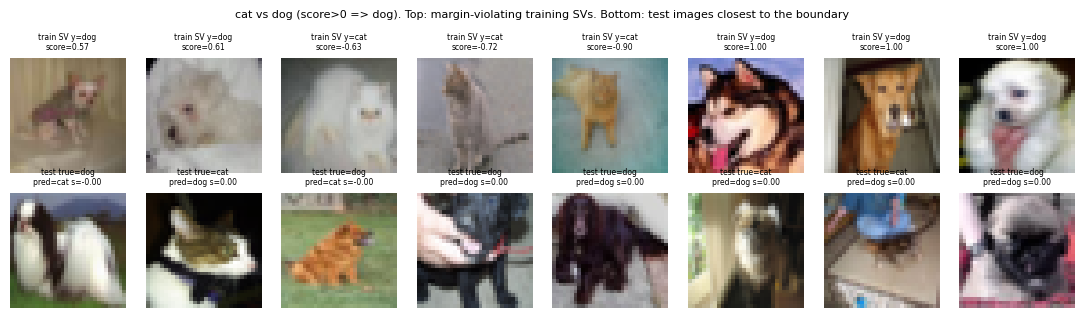

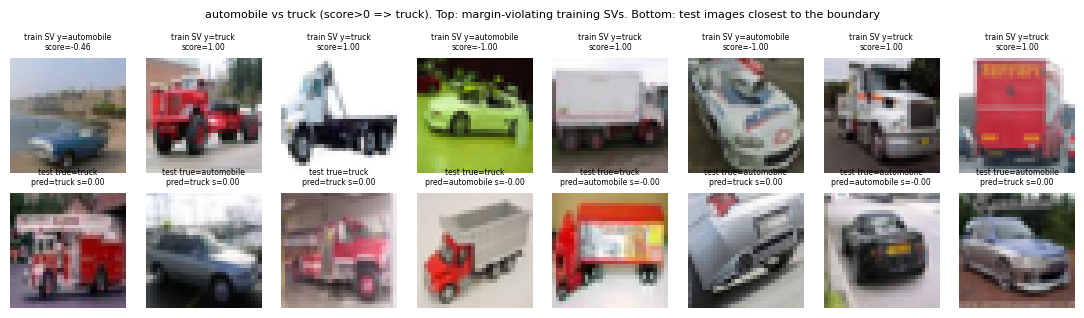

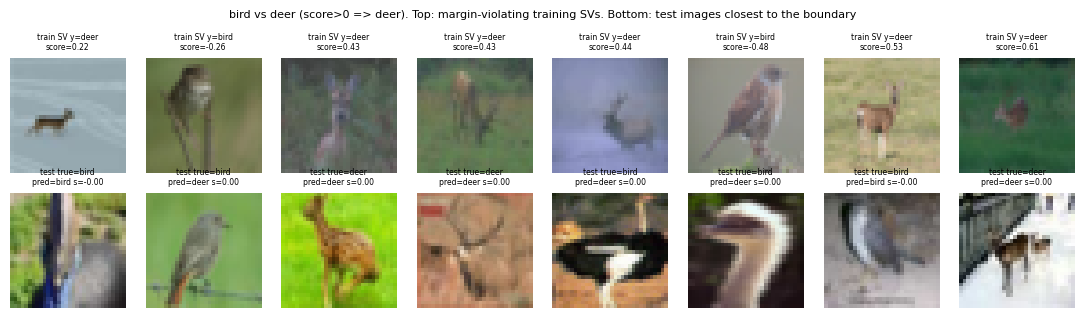

            pair  pair_test_acc  n_SV  SV_frac_pair  bound_SV_frac  mean_abs_score_errors  mean_abs_score_correct  err_rate_closest_quartile  err_rate_rest  centroid_dist_over_within_std
         cat-dog          0.610  1536         0.960          0.003                  0.346                   0.454                      0.484          0.358                          0.099
automobile-truck          0.742  1444         0.902          0.001                  0.322                   0.560                      0.426          0.203                          0.152
       bird-deer          0.692  1420         0.888          0.011                  0.354                   0.566                      0.470          0.254                          0.124
TEST clustering (kmeans, K=6):  ARI=0.0625  NMI=0.0971
             c0   c1   c2   c3   c4   c5
airplane    262  102  298  121  107  110
automobile   92  164  276  117  118  233
bird        113   52   97  100  459  179
cat         106  104   74  260  2

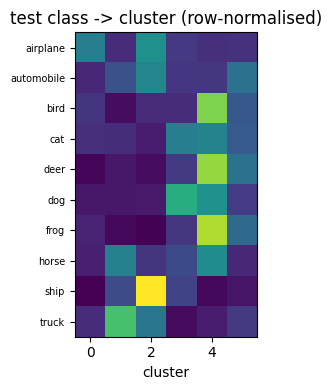

Pairs the SVM separates but clustering merges (largest gap):
                pair  svm_pair_acc  svm_separability  cluster_separability_TV   gap  shared_dominant_cluster  a_in_dom  b_in_dom
airplane-automobile         0.870             0.739                    0.196 0.543                     True     0.298     0.276
   automobile-horse         0.899             0.798                    0.310 0.488                    False     0.276     0.290
    automobile-frog         0.930             0.860                    0.382 0.478                    False     0.276     0.499
          deer-frog         0.768             0.536                    0.061 0.475                     True     0.479     0.499
          bird-frog         0.786             0.571                    0.096 0.475                     True     0.459     0.499
Pairs clustering separates more than the SVM (reverse):
      pair  svm_pair_acc  svm_separability  cluster_separability_TV   gap  shared_dominant_cluster  a_in_dom  b_in

In [14]:
# TEST (Q4): single test evaluation of the selected SVM, difficult pairs, clustering assignment & comparison
TE = get_test(); Fte = (encode(AE_SEL, TE["X"]).cpu().numpy() - mu) / sd; yte_ = TE["y"].cpu().numpy()
svm = make_svc(SEL_K, SEL_C).fit(Xs, ys); pred_te = svm.predict(Fte); acc_te = (pred_te == yte_).mean()
print(f"FINAL selected SVM ({SEL_K}, C={SEL_C:g}) TEST accuracy = {acc_te:.4f}  (evaluated once)")
cm = np.zeros((10, 10), int); np.add.at(cm, (yte_, pred_te), 1); recall = cm.diagonal() / cm.sum(1)
pair_err = {(i, j): cm[i, j] + cm[j, i] for i in range(10) for j in range(i + 1, 10)}; hard = sorted(pair_err, key=pair_err.get, reverse=True)[:3]
print("Hardest pairs (confusions in the 10-class SVM):", [(CLASSES[i], CLASSES[j], int(pair_err[(i, j)])) for i, j in hard])

def pair_clf(a, b):                                 # pairwise one-vs-one classifier = identical sub-problem libsvm solves inside the 10-class SVC
    m = (ys == a) | (ys == b); X_, y_ = Xs[m], np.where(ys[m] == b, 1, -1); clf = make_svc(SEL_K, SEL_C).fit(X_, y_); return clf, X_, y_, sub[m]
def show(ax_row, imgs, titles):
    for a, im, t in zip(ax_row, imgs, titles): a.imshow(im.permute(1, 2, 0).cpu().numpy()); a.set_title(t, fontsize=5.5); a.axis("off")
pair_stats = []
for (a, b) in hard:
    clf, X_, y_, gidx = pair_clf(a, b); f_tr = clf.decision_function(X_); marg = y_ * f_tr
    sv = clf.support_; bound = np.abs(clf.dual_coef_[0]) >= SEL_C * (1 - 1e-6)
    m = (yte_ == a) | (yte_ == b); Xp, yp = Fte[m], np.where(yte_[m] == b, 1, -1); f_te = clf.decision_function(Xp); pr = np.where(f_te > 0, 1, -1); err = pr != yp
    Xim = TE["X"][torch.tensor(np.where(m)[0], device=dev)]; ordr = np.argsort(np.abs(f_te))[:8]
    q = np.abs(f_te) <= np.quantile(np.abs(f_te), 0.25)
    cen = np.linalg.norm(X_[y_ == 1].mean(0) - X_[y_ == -1].mean(0)) / np.sqrt(0.5 * (X_[y_ == 1].var(0).sum() + X_[y_ == -1].var(0).sum()))
    pair_stats.append(dict(pair=f"{CLASSES[a]}-{CLASSES[b]}", pair_test_acc=1 - err.mean(), n_SV=len(sv), SV_frac_pair=len(sv) / len(y_), bound_SV_frac=bound.mean(),
                           mean_abs_score_errors=np.abs(f_te[err]).mean() if err.any() else np.nan, mean_abs_score_correct=np.abs(f_te[~err]).mean(),
                           err_rate_closest_quartile=err[q].mean(), err_rate_rest=err[~q].mean(), centroid_dist_over_within_std=cen))
    worst = sv[np.argsort(marg[sv])[:8]]; Xtr_im = D["Xtr"][torch.tensor(gidx[worst], device=dev)]
    fig, ax = plt.subplots(2, 8, figsize=(11, 3.2))
    show(ax[0], Xtr_im, [f"train SV y={CLASSES[b] if y_[w]==1 else CLASSES[a]}\nscore={f_tr[w]:.2f}" for w in worst])
    show(ax[1], Xim[torch.tensor(ordr, device=dev)], [f"test true={CLASSES[b] if yp[i]==1 else CLASSES[a]}\npred={CLASSES[b] if pr[i]==1 else CLASSES[a]} s={f_te[i]:.2f}" for i in ordr])
    fig.suptitle(f"{CLASSES[a]} vs {CLASSES[b]} (score>0 => {CLASSES[b]}). Top: margin-violating training SVs. Bottom: test images closest to the boundary", fontsize=8)
    plt.tight_layout(); savefig(f"q4b_pair_{CLASSES[a]}_{CLASSES[b]}")
T_q4b = pd.DataFrame(pair_stats); print(T_q4b.round(3).to_string(index=False)); T_q4b.to_csv(f"{OUT}/q4b_pairs.csv", index=False)

# Q4(c): final clustering fit on TRAIN representations; test points only ASSIGNED; labels used only afterwards for evaluation
cl = fit_cluster(CL_METHOD, CL_K); lte = cl.predict(Fte)
ARI, NMI = adjusted_rand_score(yte_, lte), normalized_mutual_info_score(yte_, lte); print(f"TEST clustering ({CL_METHOD}, K={CL_K}):  ARI={ARI:.4f}  NMI={NMI:.4f}")
cont = pd.DataFrame(np.zeros((10, CL_K), int), index=CLASSES, columns=[f"c{k}" for k in range(CL_K)])
for y_i, c_i in zip(yte_, lte): cont.iloc[y_i, c_i] += 1
print(cont.to_string()); cont.to_csv(f"{OUT}/q4c_contingency.csv")
fig, ax = plt.subplots(figsize=(6, 4)); ax.imshow(cont.values / cont.values.sum(1, keepdims=True), cmap="viridis"); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES, fontsize=7)
ax.set_xlabel("cluster"); ax.set_title("test class -> cluster (row-normalised)"); plt.tight_layout(); savefig("q4c_contingency")

P = cont.values / cont.values.sum(1, keepdims=True); rows = []                     # classification vs clustering, all 45 class pairs
for a in range(10):
    for b in range(a + 1, 10):
        clf, *_ = pair_clf(a, b); m = (yte_ == a) | (yte_ == b); acc_p = (clf.predict(Fte[m]) == np.where(yte_[m] == b, 1, -1)).mean()
        tv = 0.5 * np.abs(P[a] - P[b]).sum(); rows.append(dict(pair=f"{CLASSES[a]}-{CLASSES[b]}", svm_pair_acc=acc_p, svm_separability=2 * acc_p - 1, cluster_separability_TV=tv, gap=(2 * acc_p - 1) - tv,
                                                                  shared_dominant_cluster=P[a].argmax() == P[b].argmax(), a_in_dom=P[a].max(), b_in_dom=P[b].max()))
T_dis = pd.DataFrame(rows).sort_values("gap", ascending=False); T_dis.to_csv(f"{OUT}/q4c_svm_vs_cluster_pairs.csv", index=False)
print("Pairs the SVM separates but clustering merges (largest gap):\n", T_dis.head(5).round(3).to_string(index=False))
print("Pairs clustering separates more than the SVM (reverse):\n", T_dis.tail(3).round(3).to_string(index=False))
t0 = T_dis.iloc[0]; print(f"\nQUANTITATIVE DISAGREEMENT: {t0.pair}: SVM pairwise test accuracy {t0.svm_pair_acc*100:.1f}% (separability {t0.svm_separability:.2f}) but the clusters' total-variation separability is only "
      f"{t0.cluster_separability_TV:.2f}; {'both classes share the same dominant cluster' if t0.shared_dominant_cluster else 'classes use different dominant clusters'} "
      f"({t0.a_in_dom*100:.0f}% and {t0.b_in_dom*100:.0f}% of the two classes' test points in their own dominant cluster).")
pd.DataFrame(dict(svm_recall=recall, cluster_concentration=P.max(1)), index=CLASSES).to_csv(f"{OUT}/q4c_perclass.csv")
json.dump(dict(roll=ROLL, seed=SEED, d_sel=D_SEL, sigma=SIGMA, svm=dict(kernel=SEL_K, C=SEL_C, test_acc=float(acc_te)), clustering=dict(method=CL_METHOD, K=CL_K, ARI=ARI, NMI=NMI)),
          open(f"{OUT}/summary.json", "w"), indent=1)
print("\nAll tables/figures are in:", OUT)